# Multi-pulse ion-electron entanglement calculation

This notebook contains the **interactive calculation only**. The reusable numerical routines live in `functions.py`.


In [1]:
%load_ext autoreload
# %autoreload 2
%reload_ext autoreload

import numpy as np
import matplotlib.pyplot as plt

from functions import def_t_array, calc_field, WF_amp_Npulse, entanglement_ab
import general_functions as gf

## 1. Define the pulse sequence and system parameters


In [2]:
# System parameters
omega_0 = 1.5
z0      = 0.502
z12     = 0.37323

DtD = np.pi / (omega_0)           # Field half cycle duration 
I0  = 1.246759e+13                # Peak intensity
E0 = gf.I_to_E0(I0)               # Peak electric field
O = z12 * E0                      # Rabi Frequency
eps = np.linspace(-O, O, 500) # Numerical grid: relative photoelectron energy

# Pulse type
typ = 'gaus'      # 'gaus' or 'ftop'

# Pulse durations for one Rabi cycle i.e. 2pi pulse area 
if typ == 'ftop':
    tau_2pi = 2*np.pi/(E0 * z12)
elif typ == 'gaus':
    tau_2pi = 2*np.pi/(E0 * z12) * np.sqrt(np.log(4)/np.pi)

tau = tau_2pi * 1.5

# Pulse positions in number of field half cycles -- 
    # even: in phase, odd: out of phase, else: other phase 
    # one entry per pulse
Is = np.array([0, 2000]) 

t_Is  = DtD * Is 
EI    = E0 * np.ones(len(Is))  
tau_I = tau * np.ones(len(Is)) 

## 2. Calculate and inspect the electric field


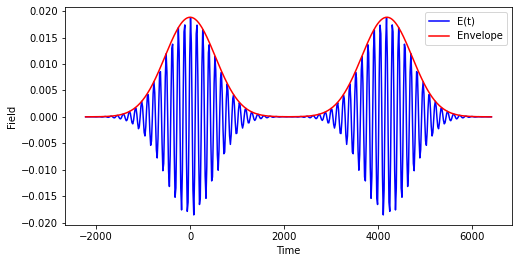

In [3]:
%reload_ext autoreload

t = def_t_array(typ, t_Is, tau_I)

Et, E_Envelope, Envelope_I, E_pos = calc_field(
    t, t_Is, EI, tau_I, omega_0, typ
)

plt.figure(figsize=(8, 4))
plt.plot(t, Et.real, 'b-', label='E(t)')
plt.plot(t, E_Envelope, 'r-', label='Envelope')
plt.xlabel('Time')
plt.ylabel('Field')
plt.legend()
plt.show()

# Note that the time array has few points as the important timescale is the slower Rabi timescale

## 3. Calculate the amplitudes & plot Rabi and Atom Pop

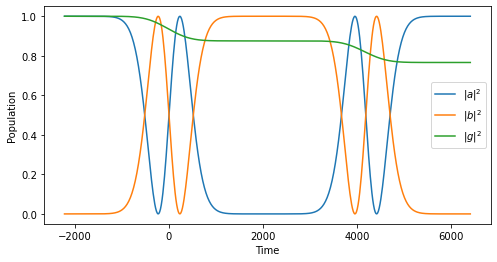

In [4]:
%reload_ext autoreload

a, b, g, c_a, c_b = WF_amp_Npulse(
    t=t,
    eps=eps,
    t_Is=t_Is,
    EI=EI,
    tau_I=tau_I,
    omega_0=omega_0,
    z12=z12,
    z0=z0,
    typ=typ,
    depletion=True,
)

plt.figure(figsize=(8, 4))
plt.plot(t, np.abs(a)**2, label=r'$|a|^2$')
plt.plot(t, np.abs(b)**2, label=r'$|b|^2$')
plt.plot(t, np.abs(g)**2, label=r'$|g|^2$')
plt.xlabel('Time')
plt.ylabel('Population')
plt.legend()
plt.show()

## 4. Plot the photoelectron spectra


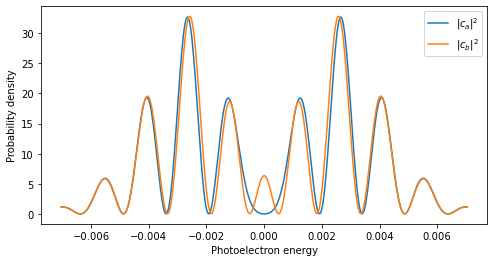

In [5]:
plt.figure(figsize=(8, 4))
plt.plot(eps, np.abs(c_a)**2, label=r'$|c_a|^2$')
plt.plot(eps, np.abs(c_b)**2, label=r'$|c_b|^2$')
plt.xlabel('Photoelectron energy')
plt.ylabel('Probability density')
plt.legend()
plt.show()


## 5. Calculate the ion-electron entanglement


In [6]:
S_ab = entanglement_ab(eps, c_a, c_b)
print(f'Entanglement entropy: {S_ab:.6f} bits')


Entanglement entropy: 0.999986 bits


## 6.Time scan

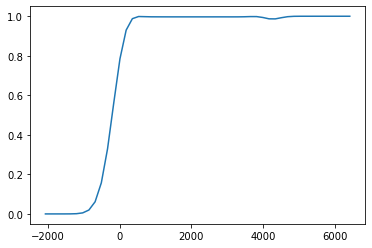

In [7]:
step_size = 10

idx = np.arange(step_size,len(t) + 1,step_size)

if idx[-1] != len(t):
    idx = np.append(idx, len(t))
    
t_scan = t[idx - 1]

SvN_arr = np.zeros(len(t_scan))

for i, j in enumerate(idx):
    
    a, b, g, c_a, c_b = WF_amp_Npulse(
        t=t[:j],
        eps=eps,
        t_Is=t_Is,
        EI=EI,
        tau_I=tau_I,
        omega_0=omega_0,
        z12=z12,
        z0=z0,
        typ=typ,
        depletion=True,
    )
    
    SvN_arr[i] = entanglement_ab(eps, c_a, c_b)
    
plt.plot(t_scan, SvN_arr)
plt.show()